In [16]:
import wfdb
import numpy as np
import os
import pandas as pd
from scipy.signal import butter, sosfiltfilt
import neurokit2

The PhysioNet 2017 dataset contains 8,528 samples ranging from 9 seconds to just over 60 seconds, each sampled at 300 Hz. They have been band passed by the AliveCor device. 

There are 5154 Normal (N) samples and 771 AF (AF) samples. The rest are labeled as Noisy (~) or Other Rhythm (O). 


In [12]:
record = wfdb.rdrecord('/Users/tristanmartin/Desktop/IIB PROJECT/datasets/PhysioNet 2017/training2017/A00001')

print(type(record.p_signal))
num_samples, num_leads = np.shape(record.p_signal)
print(num_samples)
print(num_leads)

df = pd.read_csv('/Users/tristanmartin/Desktop/IIB PROJECT/datasets/PhysioNet 2017/REFERENCE-v3.csv')
print(df.head())

<class 'numpy.ndarray'>
9000
1
   A00001  N
0  A00002  N
1  A00003  N
2  A00004  A
3  A00005  A
4  A00006  N


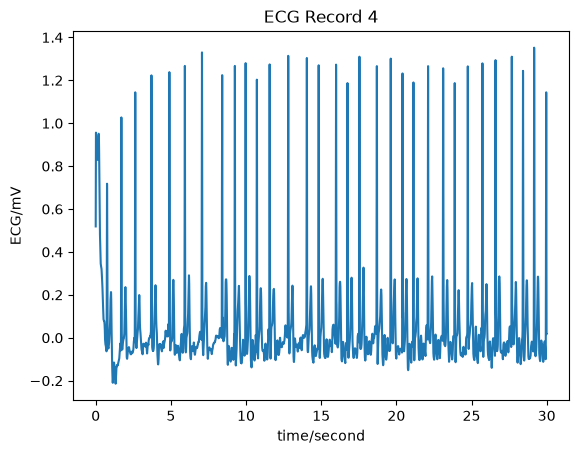

In [15]:
signal_number = 4

record = wfdb.rdrecord(f'/Users/tristanmartin/Desktop/IIB PROJECT/datasets/PhysioNet 2017/training2017/A{signal_number:05d}')

wfdb.plot_wfdb(record=record,  
                title=f'ECG Record {signal_number}', 
                time_units='seconds')

While the signals have allegedly been bandpassed already, we will re-apply a Butterworth bandpass filter. 

In [ ]:
def bandpass(signal_number, low_f = 0.5, high_f = 40, order = 4):
    record = wfdb.rdrecord(f'/Users/tristanmartin/Desktop/IIB PROJECT/datasets/PhysioNet 2017/training2017/A{signal_number:05d}')
    signal = record.p_signal[:, 0]
    fs = record.fs
    sos = butter(order, [low_f, high_f], btype = 'bandpass', fs = fs, output = 'sos')
    return sosfiltfilt(sos, signal)
